# Movie Pre-Processing

---

## Notebook summary 


- Polish movie
- Trim Zs
- Subtract Bg
- Photobleach correct (PBC)
- Align Cameras *if needed

----

## Importing libraries


----

In [2]:
# To manipulate arrays
import numpy as np 
from skimage.io import imread
from pystackreg import StackReg
import matplotlib.pyplot as plt 
import pandas as pd 
import os
# %matplotlib inline 
plt.style.use('dark_background')

# Napari 
%gui qt5 
import napari
from napari.utils import nbscreenshot
#IF YOU GET CHARMAP ISSUE DO THIS: https://github.com/vispy/vispy/issues/1330#issuecomment-1353180929
#Using Vispy 0.11.0

import tifffile



## Functions 

___

### pbc_calculation

In [3]:
def pbc_calculation(movie, N):
    """
    Correct signal decay across all frames to match the total intensity
    of each z-plane to that of the specified frame N, using NumPy array operations.
   
    Parameters:
    - movie: numpy array with dimensions (t, z, x, y, ch),
             where t = timepoints, z = z-planes, x and y = spatial dimensions, ch = channels.
    - N: int, the frame index used as the reference for intensity matching.
   
    Returns:
    - corrected_movie: numpy array with corrected signal intensities.
    """
    # Calculate the mean intensity for each z-plane and channel at each timepoint
    mean_intensities = movie.mean(axis=(2, 3))
   
    # Extract the mean intensity for the reference frame N for each z-plane and channel
    reference_intensities = mean_intensities[N, :, :]
   
    # Calculate the correction factors for each timepoint, z-plane, and channel
    correction_factors = reference_intensities / mean_intensities
   
    # Avoid division by zero by setting any infinite correction factors to 1
    correction_factors[np.isinf(correction_factors)] = 1
   
    # Ensure correction_factors shape matches movie shape for broadcasting
    correction_factors_reshaped = correction_factors[:, :, np.newaxis, np.newaxis, :]
   
    # Apply the correction factors to the entire movie
    corrected_movie = movie * correction_factors_reshaped
   
    return corrected_movie


#OLD SLOW WAY
# def pbc_calculation(movie, frame):
#     # The first dimension represents the z value, the second dimension represents the channel, and the third dimension is a list of mean intensities for each timepoint of that z and channel.
#     mean_int_in_zc = np.empty((movie.shape[1], movie.shape[4], movie.shape[0]), dtype=object)
#     img_pbc_2 = np.zeros_like(movie)
#     # Loop over each z in the movie.
#     for z in range(movie.shape[1]):
#         # Loop over each channel in the movie.
#         for channel in range(movie.shape[4]):
#             # Create an empty list to hold the mean intensity values for this z and channel.
#             mean_int_zc = []
#             # mean intensity at frame 'frame' of the masked image
#             temp_img_zero = movie[frame, z, :, :, channel].flatten()
#             mean_int_at_frame = temp_img_zero[np.nonzero(temp_img_zero)].mean()
#             # Loop over each frame in the movie.
#             for i in range(movie.shape[0]):
#                 # mean intensity at frame 'i' of the masked image
#                 temp_img = movie[i, z, :, :, channel].flatten()
#                 mean_int_at_frames = temp_img[np.nonzero(temp_img)].mean()
#                 # Simple ratio method.
#                 img_pbc_2[i, z, :, :, channel] = ((mean_int_at_frame / mean_int_at_frames) * movie[i, z, :, :, channel]).astype(np.uint16)
#                 # Calculate the mean intensity for this frame, z, and channel, excluding any zeros.
#                 # Append the result to the mean_int_zc list.
#                 mean_int_zc.append(np.mean(img_pbc_2))
#             # Convert the mean_int_zc list to a numpy array.
#             mean_int_zc = np.array(mean_int_zc)
#             # Store the mean_int_zc array in the mean_int_in_zc 3D array at the current z and channel indices.
#             mean_int_in_zc[z, channel] = mean_int_zc
#     return img_pbc_2


## Loading data (and track file, if already available)


----

In [2]:
#dir = r'\\129.82.125.210\TSnas2\galindo\1_Imaging_Data\OptoClustering\090192023_LARIAT_purowashout\Dish2'
dir = r'\\129.82.125.210\TSnas2\SharedInternal\GabeAndGretch\OptoClustering2024\LARIAT_pGG109test\20240205_44TP_15sINT_3_1'
my_output_dir = r'\\129.82.125.210\TSnas2\SharedInternal\GabeAndGretch\OptoClustering2024\LARIAT_pGG109test\20240205_44TP_15sINT_3_1'

In [3]:
#Video directory
img_4D_filename = 'Cell04.tif'
img_4D =  imread(os.path.join(dir,img_4D_filename))
img_4D.shape

(44, 13, 512, 512, 3)

In [7]:
# Converting the video to Croparray format
img_croparray = np.expand_dims(img_4D,axis=0) # 
img_croparray.shape # dimensions MUST be (fov, f , z, y, x, ch)
img_croparray.shape

#if you need to reorder dimensions
img_croparray1 = np.expand_dims(img_4D,axis=0) 
img_croparray = img_croparray1.transpose([0,1,2,3,4,5]) # dimensions MUST be (fov, f , z, y, x, ch)

print("croparray format shape [fov, f , z, y, x, ch] = ", img_croparray.shape)


croparray format shape [fov, f , z, y, x, ch] =  (1, 44, 13, 512, 512, 3)


## Best Z selection

Just view video to determine what are the best z planes

In [8]:
viewer1 = napari.view_image(img_croparray[0,:,:,:,:,1])

Now do max-projection on best-z planes

In [9]:
best_zs = [3,11]
img_bestz = img_croparray[0,:,best_zs[0]:best_zs[1]+1,:,:,0:3]
img_max = np.max(img_croparray[0,:,best_zs[0]:best_zs[1]+1,:,:],axis=1)
img_bestz.shape

(44, 9, 512, 512, 3)

In [10]:
napari.view_image(img_max[:,:,:,1])

Viewer(axes=Axes(visible=False, labels=True, colored=True, dashed=False, arrows=True), camera=Camera(center=(0.0, 255.5, 255.5), zoom=3.2544921875, angles=(0.0, 0.0, 90.0), perspective=0.0, interactive=True), cursor=Cursor(position=(1.0, 1.0, 0.0), scaled=True, size=1, style=<CursorStyle.STANDARD: 'standard'>), dims=Dims(ndim=3, ndisplay=2, last_used=0, range=((0.0, 44.0, 1.0), (0.0, 512.0, 1.0), (0.0, 512.0, 1.0)), current_step=(22, 256, 256), order=(0, 1, 2), axis_labels=('0', '1', '2')), grid=GridCanvas(stride=1, shape=(-1, -1), enabled=False), layers=[<Image layer 'Image' at 0x10ae128cee0>], scale_bar=ScaleBar(visible=False, colored=False, ticks=True, position=<Position.BOTTOM_RIGHT: 'bottom_right'>, font_size=10, unit=None), text_overlay=TextOverlay(visible=False, color=(0.5, 0.5, 0.5, 1.0), font_size=10, position=<TextOverlayPosition.TOP_LEFT: 'top_left'>, text=''), overlays=Overlays(interaction_box=InteractionBox(points=None, show=False, show_handle=False, show_vertices=False, s

## Gabe's PBC

Subtract Background

In [11]:
#Draw square in corner of image to measure the background signal
viewerbg = napari.view_image(np.max(img_max[:,:,:,1],axis=0))

c:\Users\saxto\anaconda3\envs\croparray_env\lib\site-packages\numpy\core\numeric.py:2463: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  return bool(asarray(a1 == a2).all())
c:\Users\saxto\anaconda3\envs\croparray_env\lib\site-packages\numpy\core\numeric.py:2463: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  return bool(asarray(a1 == a2).all())


In [12]:
background_mask = viewerbg.layers['Shapes'].data[0][:,-2:] 

In [13]:
mean_bgintensity_channel_0 = np.mean(img_max[:, int(np.min(background_mask[:, 0])):int(np.max(background_mask[:, 0])), int(np.min(background_mask[:, 1])):int(np.max(background_mask[:, 1])), 0])
mean_bgintensity_channel_0

mean_bgintensity_channel_1 = np.mean(img_max[:, int(np.min(background_mask[:, 0])):int(np.max(background_mask[:, 0])), int(np.min(background_mask[:, 1])):int(np.max(background_mask[:, 1])), 1])
mean_bgintensity_channel_1

print("Mean Background Intensity for Channel 0:", mean_bgintensity_channel_0)
print("Mean Background Intensity for Channel 1:", mean_bgintensity_channel_1)

Mean Background Intensity for Channel 0: 638.8800244470976
Mean Background Intensity for Channel 1: 594.6147165842287


In [14]:
#Subtract the background
img_bestz_bg = img_bestz-mean_bgintensity_channel_1
img_bestz_bg = np.clip(img_bestz_bg, 0, None)
napari.view_image(img_bestz_bg[:,:,:,:,1])

Viewer(axes=Axes(visible=False, labels=True, colored=True, dashed=False, arrows=True), camera=Camera(center=(0.0, 255.5, 255.5), zoom=3.2544921875, angles=(0.0, 0.0, 90.0), perspective=0.0, interactive=True), cursor=Cursor(position=(1.0, 1.0, 0.0, 0.0), scaled=True, size=1, style=<CursorStyle.STANDARD: 'standard'>), dims=Dims(ndim=4, ndisplay=2, last_used=0, range=((0.0, 44.0, 1.0), (0.0, 9.0, 1.0), (0.0, 512.0, 1.0), (0.0, 512.0, 1.0)), current_step=(22, 4, 256, 256), order=(0, 1, 2, 3), axis_labels=('0', '1', '2', '3')), grid=GridCanvas(stride=1, shape=(-1, -1), enabled=False), layers=[<Image layer 'Image' at 0x10ae7133790>], scale_bar=ScaleBar(visible=False, colored=False, ticks=True, position=<Position.BOTTOM_RIGHT: 'bottom_right'>, font_size=10, unit=None), text_overlay=TextOverlay(visible=False, color=(0.5, 0.5, 0.5, 1.0), font_size=10, position=<TextOverlayPosition.TOP_LEFT: 'top_left'>, text=''), overlays=Overlays(interaction_box=InteractionBox(points=None, show=False, show_han

This will create a PBC for each Z in the best z's selected

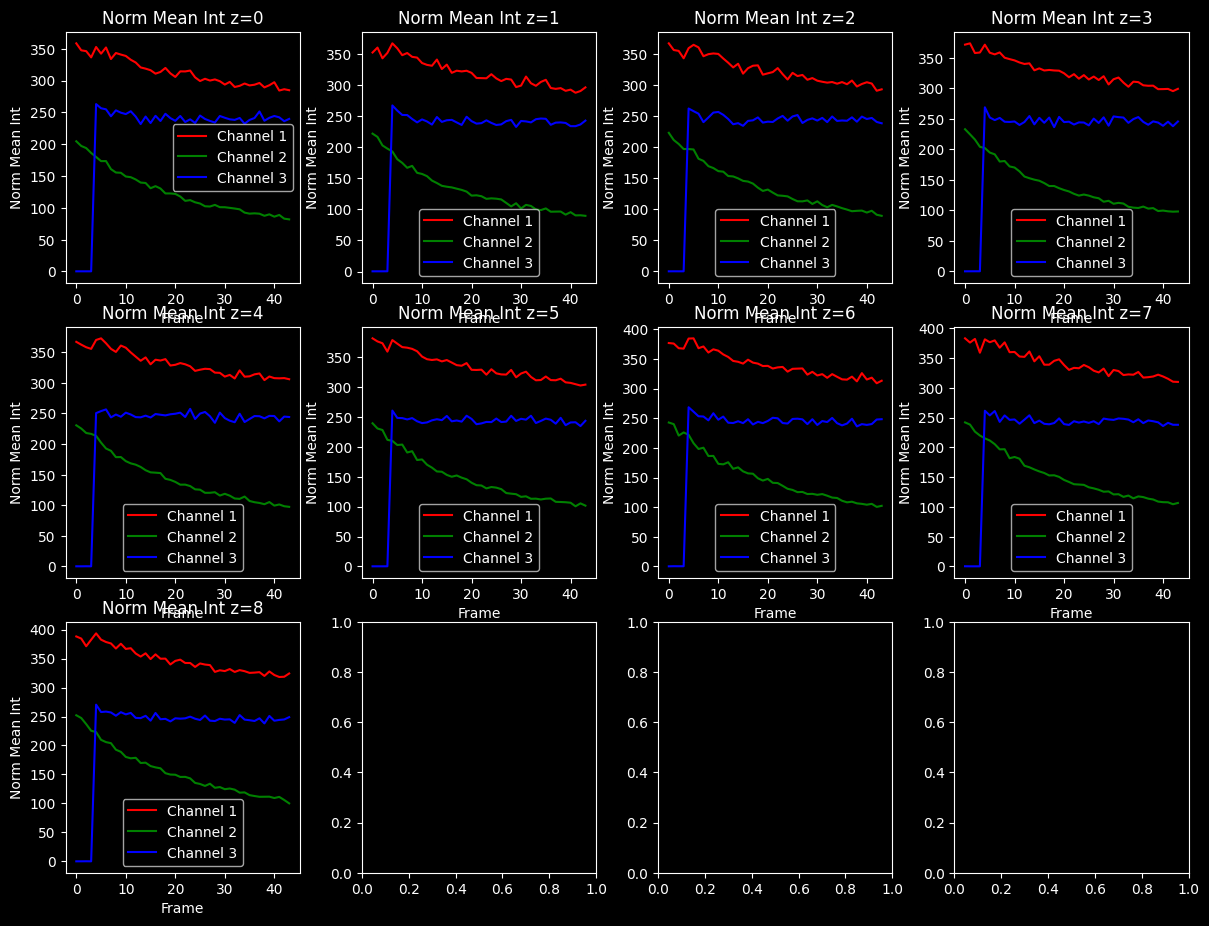

In [16]:
#Function to calculate mean intensity in all z planes for each channel
mean_intensities = img_bestz_bg.mean(axis=(2, 3))  # (movie)

colors = ['red', 'green', 'blue']

# Set plots for each Z plane
num_z_planes = img_bestz_bg.shape[1]
num_cols = 4
num_rows = (num_z_planes + num_cols - 1) // num_cols

# Create a figure with the dynamically determined number of rows and columns of subplots.
fig, axs = plt.subplots(num_rows, num_cols, figsize=(12, 3 * num_rows))
fig.tight_layout()
# Plot the data for each z.
for z in range(mean_intensities.shape[1]):

    # Calculate the row and column indices for the current subplot.
    row = z // 4
    col = z % 4

    # Loop over each channel and plot the mean intensity values for this z on the current subplot.
    for channel in range(mean_intensities.shape[2]):
        axs[row, col].plot(mean_intensities[:,z, channel], label=f"Channel {channel+1}",color=colors[channel])

    # Set the title and labels for the current subplot.
    axs[row, col].set_title('Norm Mean Int z={}'.format(z))
    axs[row, col].set_xlabel('Frame')
    axs[row, col].set_ylabel('Norm Mean Int')
    #axs[row, col].set_ylim([0.8, 600])
    axs[row, col].legend()

# Show the plots.
plt.show()

Perform photobleach correction

In [61]:
#Photobleach correct movie by z, for a given channel
img_bestz_pbc = pbc_calculation(img_bestz_bg, 5) #(Movie, reference timepoint to pbc)
pbc_viewer = napari.view_image(img_bestz_pbc[:,:,:,:,1],colormap='green')
pbc_viewer.add_image(img_bestz_pbc[:,:,:,:,0],colormap='red')
pbc_viewer.add_image(img_bestz_pbc[:,:,:,:,2],colormap='blue')
img_bestz_pbc.shape

# May have to rotate dimensions on Napari

(44, 9, 512, 512, 3)

If you want to check pbc results plotted (should be flat line)

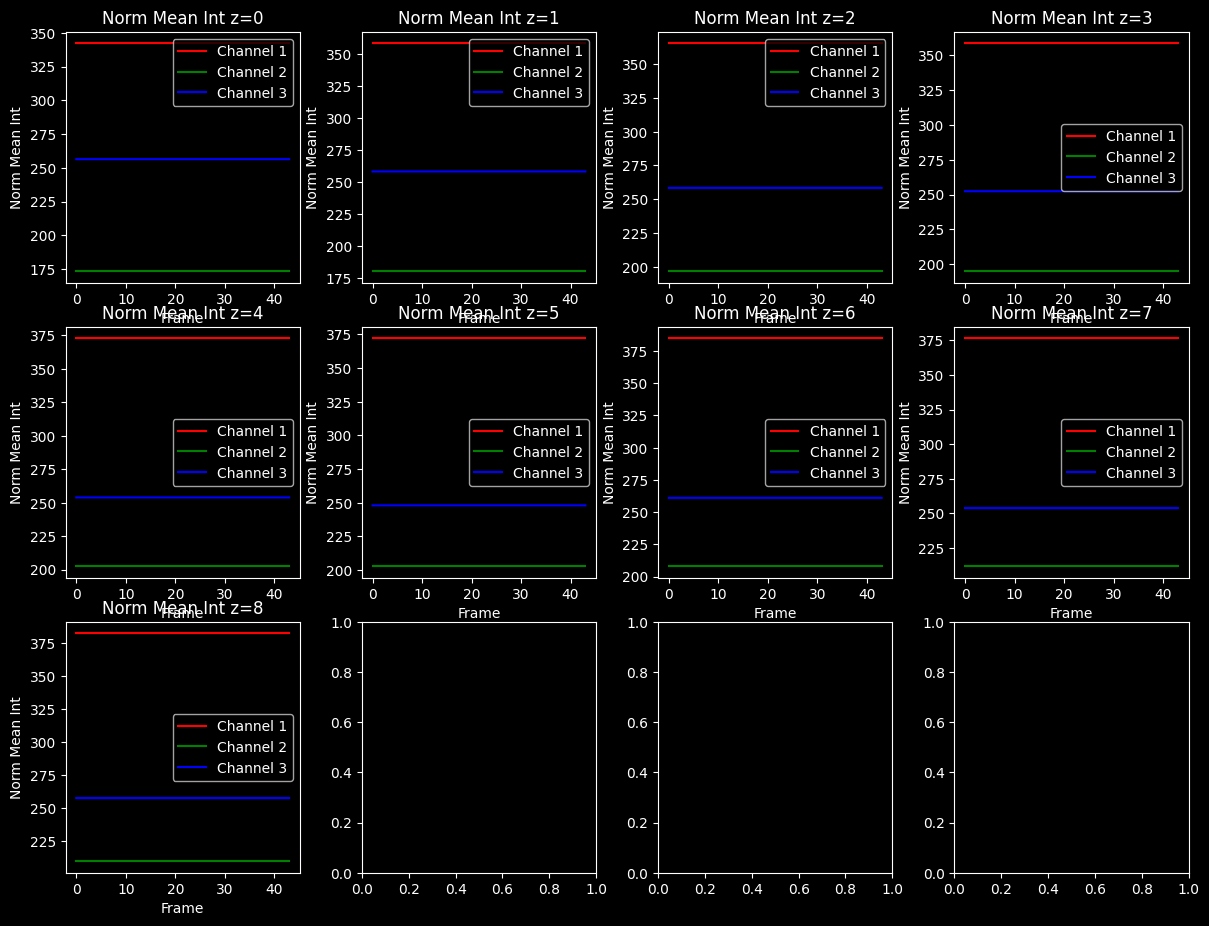

In [62]:
#Function to calculate mean intensity in all z planes for each channel
mean_intensities = img_bestz_pbc.mean(axis=(2, 3))  # (movie)

colors = ['red', 'green', 'blue']

# Set plots for each Z plane
num_z_planes = img_bestz_pbc.shape[1]
num_cols = 4
num_rows = (num_z_planes + num_cols - 1) // num_cols

# Create a figure with the dynamically determined number of rows and columns of subplots.
fig, axs = plt.subplots(num_rows, num_cols, figsize=(12, 3 * num_rows))
fig.tight_layout()
# Plot the data for each z.
for z in range(mean_intensities.shape[1]):

    # Calculate the row and column indices for the current subplot.
    row = z // 4
    col = z % 4

    # Loop over each channel and plot the mean intensity values for this z on the current subplot.
    for channel in range(mean_intensities.shape[2]):
        axs[row, col].plot(mean_intensities[:,z, channel], label=f"Channel {channel+1}",color=colors[channel])

    # Set the title and labels for the current subplot.
    axs[row, col].set_title('Norm Mean Int z={}'.format(z))
    axs[row, col].set_xlabel('Frame')
    axs[row, col].set_ylabel('Norm Mean Int')
    #axs[row, col].set_ylim([0.8, 600])
    axs[row, col].legend()

# Show the plots.
plt.show()

Expand dimension for croparray

In [63]:
img_bestz_croparray = np.expand_dims(img_bestz_pbc,axis=0)
img_bestz_croparray.shape

(1, 44, 9, 512, 512, 3)

Align RAM to CAM

In [64]:
matrix_path = r'\\129.82.125.210\TSnas2\SharedInternal\GabeAndGretch\OptoClustering2024\Beads\012224\transformation_matrix.txt'

matrix = np.genfromtxt(matrix_path, delimiter=' ')
matrix

array([[ 9.98816344e-01, -4.75553559e-03, -4.98995611e-01],
       [ 3.26781265e-03,  9.96814251e-01, -3.46799786e+00],
       [ 0.00000000e+00,  0.00000000e+00,  1.00000000e+00]])

In [65]:
sr = StackReg(StackReg.AFFINE)

transformed_img_movie = np.copy(img_bestz_pbc)
for z in range(img_bestz_pbc.shape[1]):
    for t in range(img_bestz_pbc.shape[0]):
        # Apply transformation to channel 0 for the current z and t
        transformed_channel0 = sr.transform(img_bestz_pbc[t, z, :, :, 0], matrix)
        
        # Replace the original channel 0 with the transformed channel
        transformed_img_movie[t, z, :, :, 0] = transformed_channel0

In [66]:
transformed_img_movie = np.clip(transformed_img_movie, 0, 65535)
img_bestz_croparray_transformed = np.expand_dims(transformed_img_movie,axis=0)
img_bestz_croparray_transformed.shape

(1, 44, 9, 512, 512, 3)

Save PBC movie

In [67]:
#Identify the shape order needed for Tif, what works for me is (time, z, channel, x, y)
img_bestz_pbc_transpose = transformed_img_movie.transpose([0,1,4,2,3]) 
img_bestz_pbc_transpose.shape
img_uint16 = img_bestz_pbc_transpose.astype(np.uint16)

In [68]:
#Exports the PBC movie to output directory
output_file = os.path.join(my_output_dir,img_4D_filename[:-4]+'_pbc_transformed.tif')
tifffile.imwrite(output_file, img_uint16, imagej=True)